# 03 · Machine Learning (Data Science Component)
**Cross-Platform Social Media Trend Intelligence & Prediction System**

Trains and evaluates the two traditional ML models:
- **Logistic Regression** (baseline)
- **Random Forest** (main Data Science model)

Target: `trend_label` (Low / Moderate / High)

In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)

from utils.preprocessing import build_processed_dataframe, prepare_model_data, MODEL_FEATURES

DATASET_PATH = os.path.join('..', 'dataset', 'social_media_trends.csv')
MODELS_DIR = os.path.join('..', 'models')
LABELS = ['Low', 'Moderate', 'High']

## 1. Feature Selection & Train/Test Split

In [2]:
df = build_processed_dataframe(DATASET_PATH)
X_train, X_test, y_train, y_test, transformers = prepare_model_data(df, save_dir=MODELS_DIR)
print("Features used:", MODEL_FEATURES)
print("X_train:", X_train.shape, " X_test:", X_test.shape)

Features used: ['platform', 'category', 'views', 'likes', 'comments', 'shares', 'growth_rate', 'sentiment_score', 'engagement_rate']
X_train: (6400, 9)  X_test: (1600, 9)


## 2. Logistic Regression (Baseline)

In [3]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_test)

print(classification_report(y_test, y_pred_lr, target_names=LABELS))

              precision    recall  f1-score   support

         Low       0.98      0.98      0.98       599
    Moderate       0.95      0.96      0.96       617
        High       0.96      0.95      0.95       384

    accuracy                           0.97      1600
   macro avg       0.97      0.96      0.96      1600
weighted avg       0.97      0.97      0.97      1600



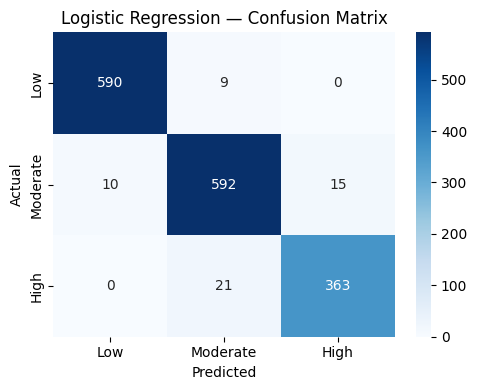

In [4]:
cm_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(5,4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS)
plt.title('Logistic Regression — Confusion Matrix')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.show()

## 3. Random Forest (Main Data Science Model)

In [5]:
rf = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=3,
                             random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print(classification_report(y_test, y_pred_rf, target_names=LABELS))

              precision    recall  f1-score   support

         Low       0.99      0.98      0.99       599
    Moderate       0.97      0.98      0.98       617
        High       0.99      0.98      0.98       384

    accuracy                           0.98      1600
   macro avg       0.98      0.98      0.98      1600
weighted avg       0.98      0.98      0.98      1600



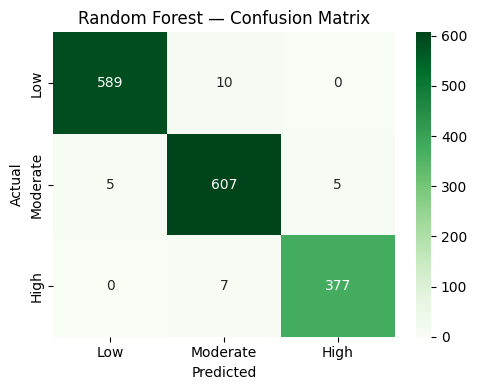

In [6]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(5,4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', xticklabels=LABELS, yticklabels=LABELS)
plt.title('Random Forest — Confusion Matrix')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout()
plt.show()

## 4. Feature Importance (Random Forest)

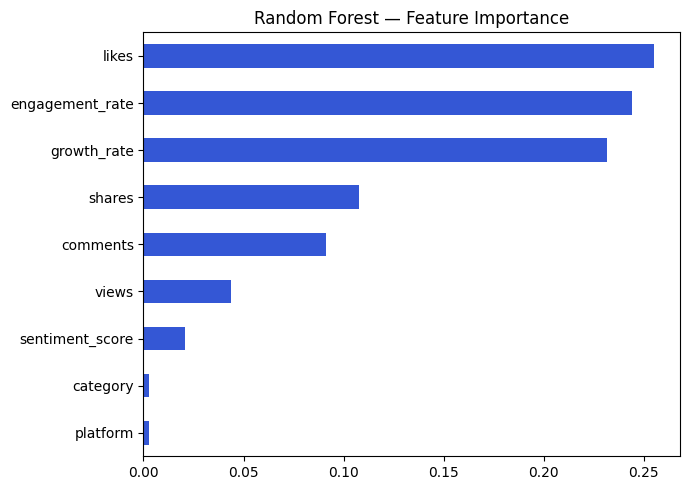

In [7]:
importances = pd.Series(rf.feature_importances_, index=MODEL_FEATURES).sort_values()
plt.figure(figsize=(7,5))
importances.plot(kind='barh', color='#3457D5')
plt.title('Random Forest — Feature Importance')
plt.tight_layout()
plt.show()

## 5. Save Models

In [8]:
joblib.dump(log_reg, os.path.join(MODELS_DIR, 'logistic_regression.pkl'))
joblib.dump(rf, os.path.join(MODELS_DIR, 'random_forest.pkl'))

def evaluate(y_true, y_pred, name):
    return {
        'model': name,
        'accuracy': round(accuracy_score(y_true, y_pred), 4),
        'precision': round(precision_score(y_true, y_pred, average='macro', zero_division=0), 4),
        'recall': round(recall_score(y_true, y_pred, average='macro', zero_division=0), 4),
        'f1_score': round(f1_score(y_true, y_pred, average='macro', zero_division=0), 4),
    }

print("Logistic Regression:", evaluate(y_test, y_pred_lr, 'Logistic Regression'))
print("Random Forest:      ", evaluate(y_test, y_pred_rf, 'Random Forest'))
print("\nModels saved to:", MODELS_DIR)

Logistic Regression: {'model': 'Logistic Regression', 'accuracy': 0.9656, 'precision': 0.9651, 'recall': 0.9633, 'f1_score': 0.9642}
Random Forest:       {'model': 'Random Forest', 'accuracy': 0.9831, 'precision': 0.9837, 'recall': 0.983, 'f1_score': 0.9833}

Models saved to: ../models


## Summary
Random Forest outperforms the Logistic Regression baseline on every metric,
which is expected since the Trend Score/Label boundaries are non-linear
combinations of the input features — a tree ensemble captures that
non-linearity better than a linear model. `likes`, `engagement_rate` and
`growth_rate` are the most influential features, consistent with the EDA
correlation analysis.